# 02 · Búsqueda no informada e informada en grillas

**Objetivo:** comparar BFS, UCS, Greedy, A* y Weighted A* en el mismo mapa, y entender qué
propiedades de la heurística (admisibilidad, consistencia, informatividad) explican el resultado.

Reglas de la grilla (las de los benchmarks de Moving AI): 8 vecinos, costo 1 cardinal y √2
diagonal, sin cortar esquinas.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from itertools import pairwise

from ai_foundations import astar, breadth_first, greedy_best_first, uniform_cost
from ai_foundations.problems.grid import GridMap, GridPathProblem, euclidean, manhattan, octile
from ai_foundations.viz import plot_search


def make_map(seed=0, width=60, height=36, density=0.10):
    """Obstáculos aleatorios + una ‘copa’ en U abierta hacia el inicio, con la meta detrás."""
    r = np.random.default_rng(seed)
    blocked = r.random((height, width)) < density
    blocked[6:30, 38] = True  # fondo de la U
    blocked[6, 22:39] = True  # brazo superior
    blocked[29, 22:39] = True  # brazo inferior
    blocked[:, :3] = blocked[:, -3:] = False
    return GridMap(["".join("T" if b else "." for b in row) for row in blocked])


def path_cost(path):
    return sum(1.0 if a[0] == b[0] or a[1] == b[1] else 2**0.5 for a, b in pairwise(path))


GRID = make_map()
START, GOAL = (1, 18), (58, 18)
problem = GridPathProblem(GRID, START, GOAL)

## 1. Cinco algoritmos, un mapa

Inicio a la izquierda, meta a la derecha, y entre ambos una “copa” en U abierta hacia el inicio:
la línea recta lleva a un callejón sin salida. Es el caso en que una heurística puramente
geométrica “engaña”.

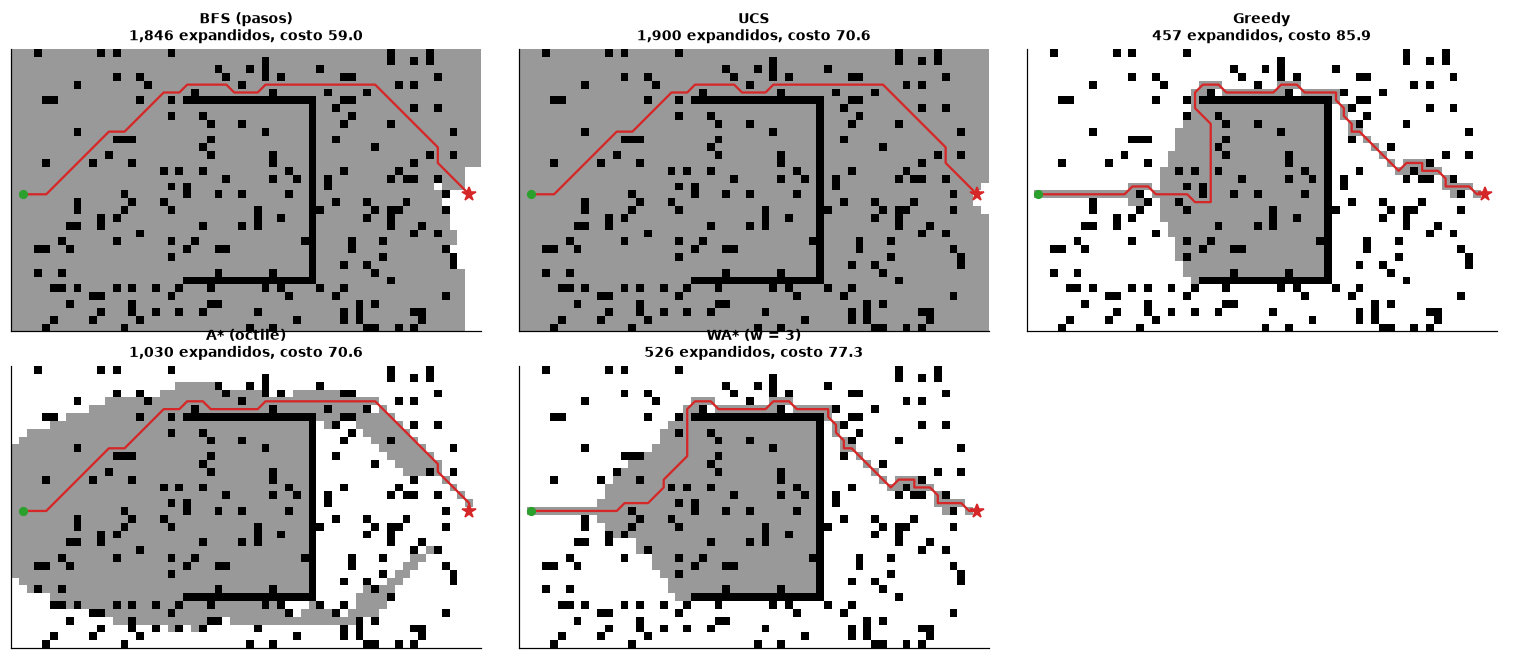

In [2]:
runs = {
    "BFS (pasos)": breadth_first(problem, record=True),
    "UCS": uniform_cost(problem, record=True),
    "Greedy": greedy_best_first(problem, octile(GOAL), record=True),
    "A* (octile)": astar(problem, octile(GOAL), record=True),
    "WA* (w = 3)": astar(problem, octile(GOAL), weight=3, record=True),
}
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, (name, res) in zip(axes.flat, runs.items(), strict=False):
    plot_search(ax, GRID, res, name)
axes.flat[-1].axis("off")
fig.tight_layout()

In [3]:
print(f"{'algoritmo':<14}{'costo real':>11}{'expandidos':>12}{'frontera máx':>14}")
for name, res in runs.items():
    print(f"{name:<14}{path_cost(res.path):>11.2f}{res.expanded:>12}{res.max_frontier:>14}")

algoritmo      costo real  expandidos  frontera máx
BFS (pasos)         70.60        1846            62
UCS                 70.60        1900            66
Greedy              85.87         457           136
A* (octile)         70.60        1030           286
WA* (w = 3)         77.28         526           140


- **BFS** minimiza el número de *pasos*, no el costo: trata la diagonal (√2) como 1. Aquí su
  camino coincide en costo con el óptimo, pero no hay ninguna garantía de que así sea.
- **UCS** es óptima pero expande en círculos concéntricos de costo: no sabe dónde está la meta.
- **Greedy** se lanza hacia la meta, choca con el laberinto y su camino puede ser malo.
- **A*** combina ambos: óptima con heurística admisible y, con heurística consistente, ningún
  algoritmo óptimo que use la misma heurística expande (esencialmente) menos nodos.

## 2. Qué heurística usar

Para una grilla 8-conectada:

| Heurística | Admisible | Comentario |
|---|---|---|
| Euclidiana | sí | subestima las rutas en escalera |
| Octile | sí | exacta en mapa vacío: la mejor sin precómputo |
| Manhattan | **no** | sobreestima las diagonales: A* puede devolver caminos subóptimos |

In [4]:
free = GRID.free_cells()
pairs = [tuple(free[i] for i in rng.choice(len(free), 2, replace=False)) for _ in range(60)]
optimal = {pair: astar(GridPathProblem(GRID, *pair), octile(pair[1])).cost for pair in pairs}
for name, make_h in [("euclidiana", euclidean), ("octile", octile), ("manhattan", manhattan)]:
    res = {pair: astar(GridPathProblem(GRID, *pair), make_h(pair[1])) for pair in pairs}
    exp = np.mean([r.expanded for r in res.values()])
    worse = sum(r.cost > optimal[pair] + 1e-9 for pair, r in res.items())
    print(f"{name:<11} expandidos (media) = {exp:7.1f}   subóptimos = {worse}/{len(pairs)}")

euclidiana  expandidos (media) =   330.0   subóptimos = 0/60
octile      expandidos (media) =   274.4   subóptimos = 0/60
manhattan   expandidos (media) =   241.2   subóptimos = 20/60


Manhattan expande menos porque **sobreestima**, y por eso pierde la garantía de optimalidad:
se comporta como un Weighted A* con peso variable y sin cota explícita.

## 3. Weighted A*: la perilla calidad–velocidad

$f = g + w\,h$ garantiza costo $\le w \cdot C^*$. En la práctica la pérdida suele ser mucho menor
que la cota, y el ahorro de nodos, grande.

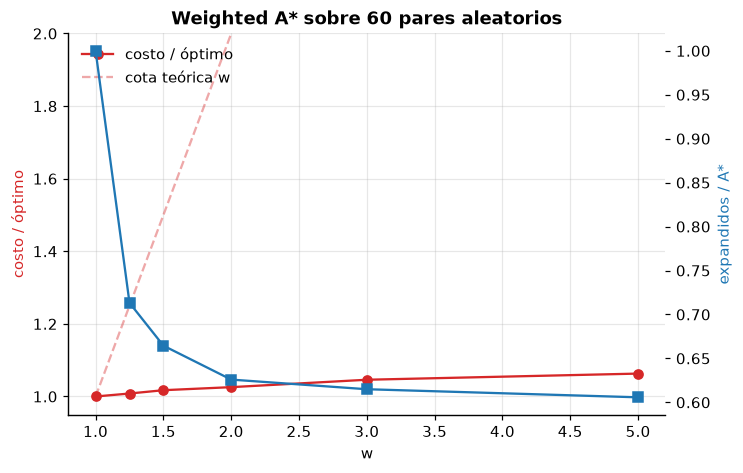

In [5]:
weights = [1.0, 1.25, 1.5, 2.0, 3.0, 5.0]
ratio, exp = [], []
for w in weights:
    r_, e_ = [], []
    for s, t in pairs:
        p = GridPathProblem(GRID, s, t)
        opt = astar(p, octile(t))
        res = astar(p, octile(t), weight=w)
        r_.append(res.cost / opt.cost)
        e_.append(res.expanded / opt.expanded)
    ratio.append(np.mean(r_))
    exp.append(np.mean(e_))

fig, ax1 = plt.subplots()
ax1.plot(weights, ratio, "o-", color="C3", label="costo / óptimo")
ax1.plot(weights, weights, "--", color="C3", alpha=0.4, label="cota teórica w")
ax1.set_xlabel("w")
ax1.set_ylabel("costo / óptimo", color="C3")
ax1.set_ylim(0.95, 2.0)
ax2 = ax1.twinx()
ax2.plot(weights, exp, "s-", color="C0")
ax2.set_ylabel("expandidos / A*", color="C0")
ax2.grid(False)
ax1.legend(loc="upper left")
ax1.set_title(f"Weighted A* sobre {len(pairs)} pares aleatorios");

## Para llevar

- Admisible ⇒ A* óptima. Consistente ⇒ además nunca necesita reabrir nodos.
- Entre dos heurísticas admisibles, la mayor (más informada) nunca expande más.
- Octile es la base en grillas; para mapas con obstáculos, heurísticas con precómputo (ALT, el
  proyecto) capturan la estructura que octile ignora.